# 2. Exploración

Qué separa a los nuevos de los usados y qué se puede usar para predecir. Cada sección viene de `eda/`. El mismo contenido se genera con `run_eda.py` en `outputs/eda/REPORTE_EDA.md`.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

from carga import cargar_train_test
import config
from eda import Contexto, calidad, contexto, relaciones, variables
from eda.graficos import estilo
from eda.reporte import Reporte
import features
import modelo

estilo()
train, test = features.construir(*cargar_train_test())
train["y"] = modelo.y_binario(train)
ctx = Contexto(train=train, test=test, reporte=Reporte(config.OUTPUTS / "eda", "Exploración"))

## Primero, la calidad de los datos

Si train y test vienen de la misma distribución, validar con folds al azar es representativo del leaderboard (D01).

# Exploración


## 1. Calidad de datos

Train tiene 70,000 filas y test 30,000. Después de aplanar el JSON y
agregar features derivadas quedan 170 columnas. Se descartaron por ser
constantes o vacías, o por repetir el título y la primera foto (las URL): `site_id`, `listing_source`, `international_delivery_mode`, `coverage_areas`, `differential_pricing`, `subtitle`, `permalink`, `thumbnail`, `secure_thumbnail`.

Columnas con faltantes y tasa de usados según la presencia del campo:

|                                |   nulos_train |   nulos_test |   usados_si_nulo |   usados_si_presente |
|:-------------------------------|--------------:|-------------:|-----------------:|---------------------:|
| catalog_product_id             |         1     |        1     |            0.463 |                0.714 |
| original_price                 |         0.999 |        0.999 |            0.464 |                0     |
| attr_estado                    |         0.995 |        0.995 |            0.462 |                0.712 |
| attr_unico_duenio              |         0.993 |        0.992 |            0.46  |                0.908 |
| attr_antiguedad                |         0.993 |        0.993 |            0.462 |                0.64  |
| official_store_id              |         0.992 |        0.992 |            0.467 |                0.03  |
| attr_kilometros                |         0.988 |        0.987 |            0.458 |                0.867 |
| attr_anio                      |         0.988 |        0.987 |            0.458 |                0.86  |
| attr_anios_de_uso              |         0.988 |        0.987 |            0.458 |                0.86  |
| video_id                       |         0.97  |        0.971 |            0.47  |                0.23  |
| warranty                       |         0.609 |        0.608 |            0.516 |                0.38  |
| seller_seg_desde_previo        |         0.359 |        0.359 |            0.464 |                0.462 |
| seller_std_log_price           |         0.25  |        0.249 |            0.506 |                0.449 |
| parent_item_id                 |         0.23  |        0.232 |            0.452 |                0.466 |
| pic_mes_mas_viejo              |         0.081 |        0.084 |            0.666 |                0.445 |
| pic_max_alto                   |         0.008 |        0.009 |            0.684 |                0.461 |
| pic_min_lado                   |         0.008 |        0.009 |            0.684 |                0.461 |
| pic_max_ancho                  |         0.008 |        0.009 |            0.684 |                0.461 |
| pic_lado_max                   |         0.008 |        0.009 |            0.684 |                0.461 |
| pic_frac_cuadradas             |         0.008 |        0.008 |            0.68  |                0.461 |
| pic_frac_id_fechado            |         0.008 |        0.008 |            0.68  |                0.461 |
| pic0_alto                      |         0.008 |        0.008 |            0.68  |                0.461 |
| pic0_ancho                     |         0.008 |        0.008 |            0.68  |                0.461 |
| pic0_aspecto                   |         0.008 |        0.008 |            0.68  |                0.461 |
| pal_frac_iq_1_media            |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_free_media            |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_free_max              |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_repuso_stock_media    |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_iq_1_max              |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_price_decimales_media |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_price_decimales_max   |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_foto_cuadrada_media   |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_repuso_stock_max      |         0.002 |        0.003 |            0.536 |                0.463 |
| pal_frac_foto_cuadrada_max     |         0.002 |        0.003 |            0.536 |                0.463 |
| seller_state                   |         0     |        0     |            0.5   |                0.463 |

La ausencia no es aleatoria. Tener `official_store_id`, `video_id` o `warranty`
cargados se asocia a items nuevos: son campos que completan los vendedores
profesionales. Las fotos (`pic_*`) faltan solo cuando el item no tiene ninguna, y en
ese caso el item suele ser usado.


## 2. Target

Clases bastante balanceadas: 37,588 `new` (53.7%) y
32,412 `used` (46.3%). Predecir siempre `new`
da un accuracy de 0.537, ese es el piso. Como la métrica es
accuracy y las clases están balanceadas, no hace falta reponderar.


## 3. Identificadores



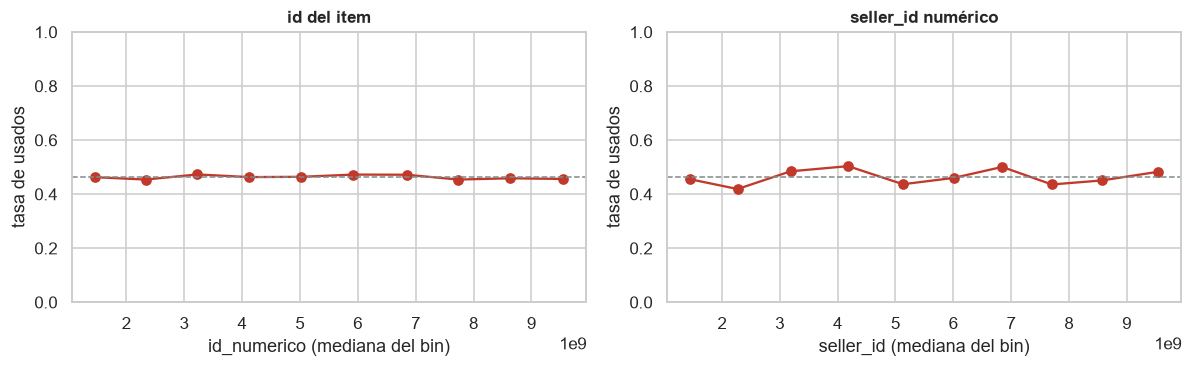



*Tasa de usados por deciles de los ids numéricos*

Los ids están anonimizados: van uniformes de 1e9 a 1e10, no correlacionan con la
fecha de creación (r = 0.0008) y la tasa de usados es plana en todos los deciles.
Lo mismo con `seller_id` y `parent_item_id` (que además casi nunca apunta a un item
del dataset: 0.0014%). Su valor numérico no sirve, pero `seller_id` como
**clave de agrupación** es de lo más valioso del dataset (ver sección de vendedores).


## 4. Train vs test (adversarial validation)

Un LightGBM entrenado para distinguir filas de train y de test obtiene AUC = 0.497
con validación cruzada. Un valor cercano a 0.5 indica que ambos vienen de la misma
distribución (split aleatorio, no temporal), así que una validación cruzada
estratificada sobre train debería ser representativa del leaderboard.

Solapamiento de grupos: 71.6% de los items de test tienen un
vendedor que aparece en train y 94.7% una categoría que aparece
en train. Esto habilita target encoding por vendedor y por categoría (siempre
out-of-fold para no filtrar el target).


In [2]:
calidad.calidad_datos(ctx)
calidad.target(ctx)
calidad.ids(ctx)
calidad.train_vs_test(ctx)
ctx.reporte.mostrar()

## Después, cada variable por separado


## 5. Variables categóricas



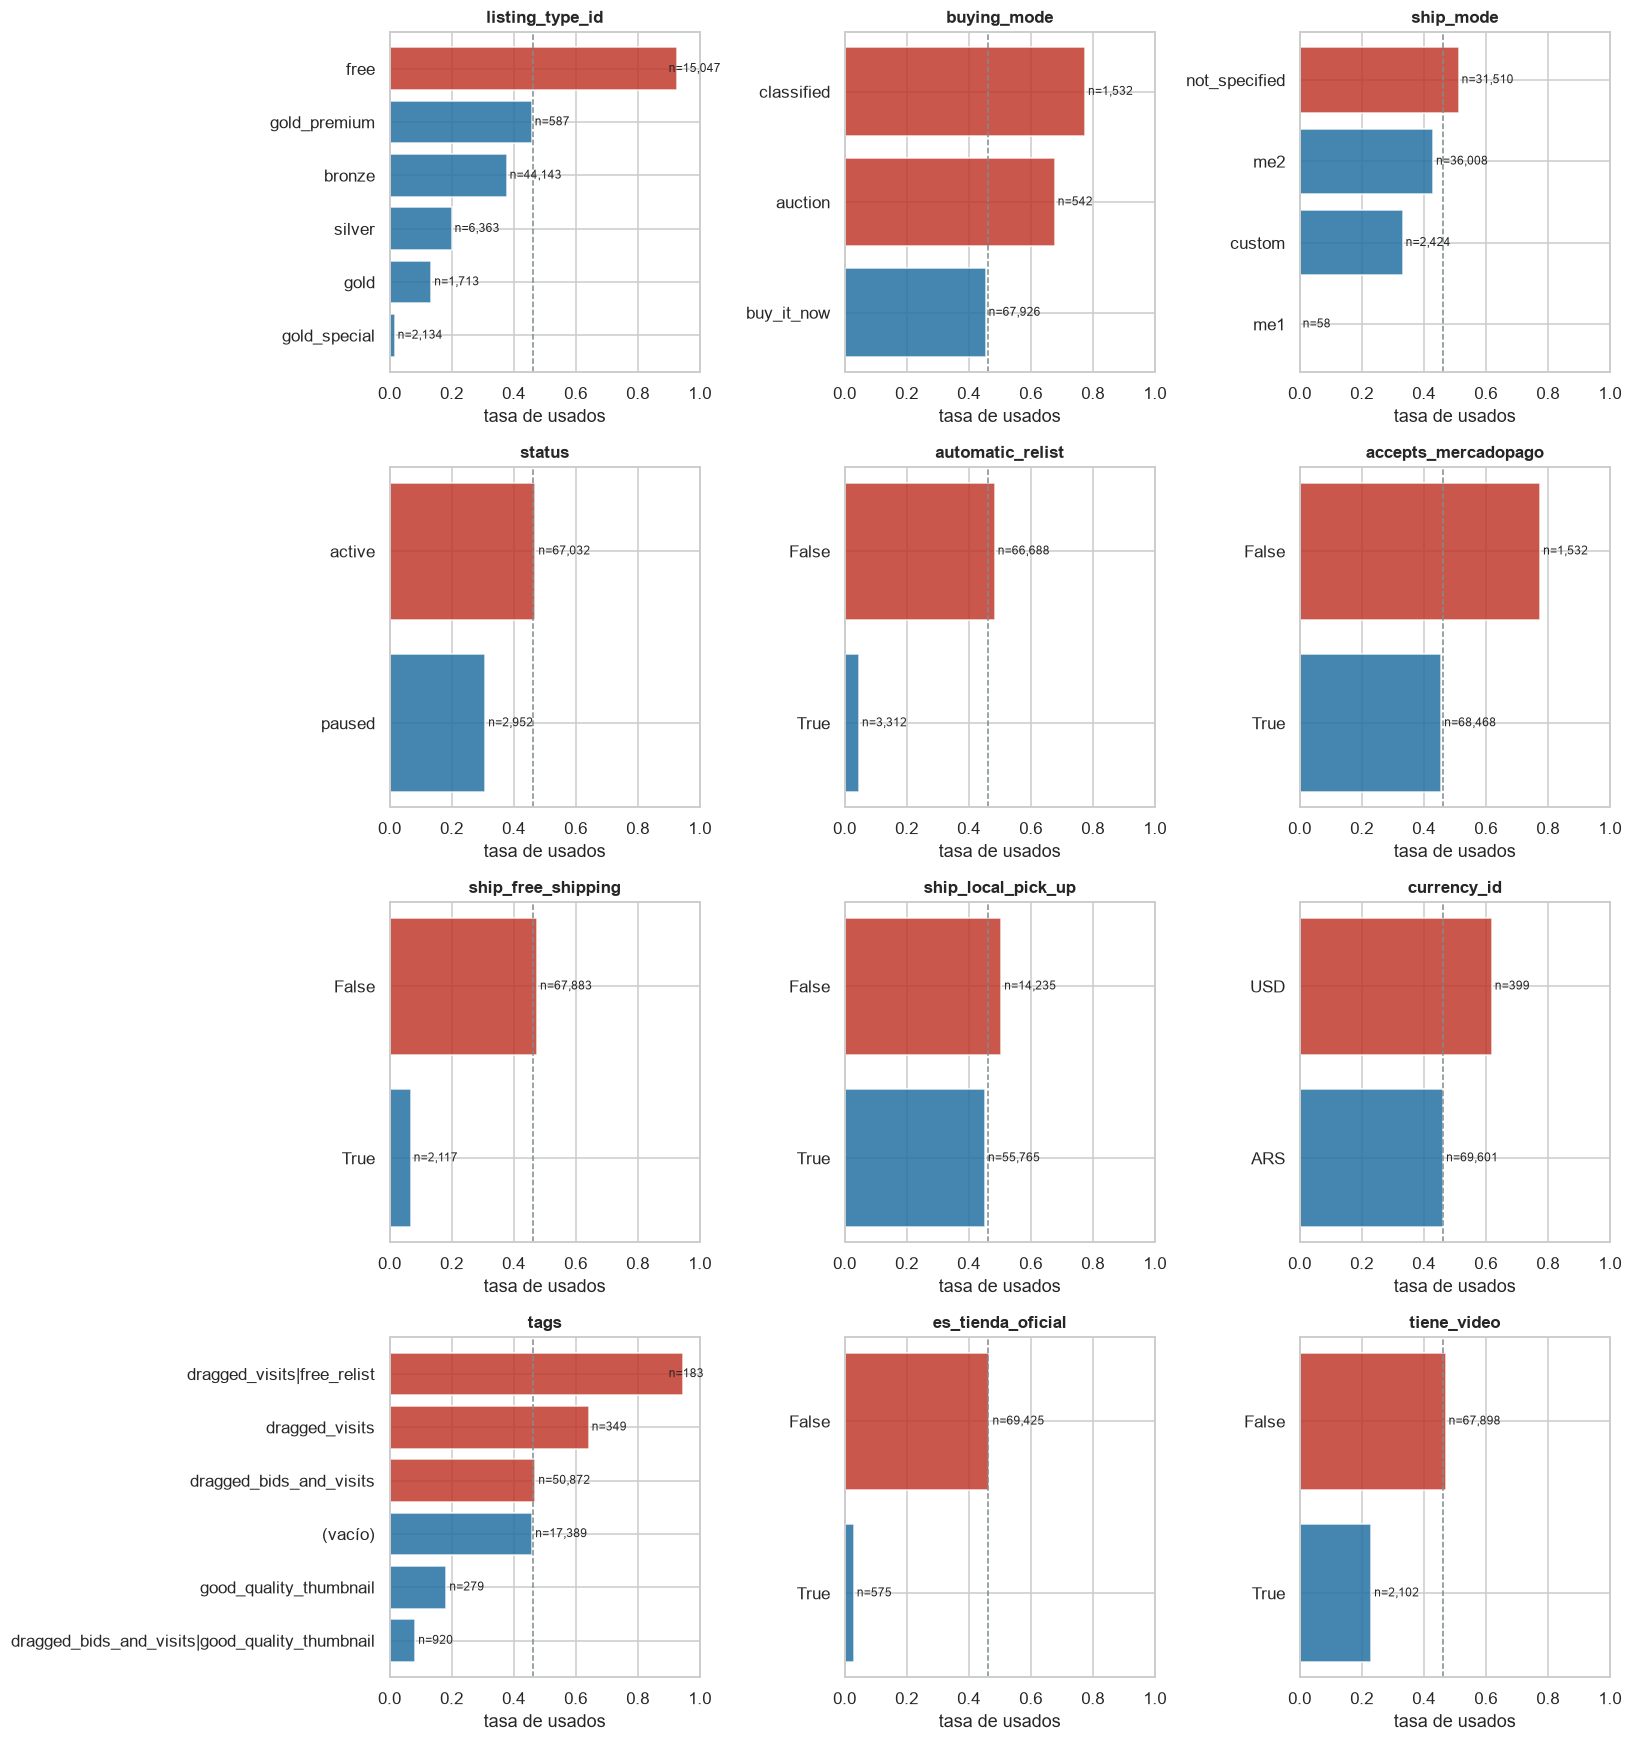



*Tasa de usados por nivel (rojo: por encima de la tasa global)*

Diferencia entre la tasa máxima y mínima de usados entre niveles (n >= 30):

|                     |   rango_tasa |
|:--------------------|-------------:|
| listing_type_id     |        0.911 |
| tags                |        0.863 |
| ship_mode           |        0.512 |
| automatic_relist    |        0.438 |
| es_tienda_oficial   |        0.437 |
| ship_free_shipping  |        0.407 |
| buying_mode         |        0.321 |
| accepts_mercadopago |        0.319 |
| tiene_video         |        0.24  |
| status              |        0.162 |
| currency_id         |        0.157 |
| ship_local_pick_up  |        0.052 |

- `listing_type_id` es la categórica más fuerte: las publicaciones `free` son
  92.7% usadas. Publicar gratis es típico del particular que vende algo propio,
  mientras que `gold_special` (la más cara) es casi exclusivamente de nuevos.
- `automatic_relist` = True (4.6% usados), envío gratis, tienda oficial y
  video son marcas de vendedor profesional y empujan hacia "nuevo".
- `buying_mode` `classified` y `auction` son mayormente usados (clasificados de
  autos e inmuebles, subastas de objetos de colección).


### Medios de pago no MercadoPago

|                                  |     n |   tasa_usados |
|:---------------------------------|------:|--------------:|
| MLAMP (MercadoPago)              |   495 |         0     |
| MLAOT (Tarjeta de crédito)       | 17229 |         0.292 |
| MLATB (Transferencia bancaria)   | 35995 |         0.389 |
| MLAMO (Efectivo)                 | 46910 |         0.445 |
| MLAVS (Visa)                     |   492 |         0.5   |
| MLAMC (MasterCard)               |   450 |         0.511 |
| MLAVE (Visa Electron)            |   450 |         0.516 |
| MLACD (Contra reembolso)         |   439 |         0.519 |
| MLAAM (American Express)         |   422 |         0.521 |
| MLAMS (Mastercard Maestro)       |   443 |         0.526 |
| MLAWC (Acordar con el comprador) |  5588 |         0.547 |
| MLADC (Diners)                   |   331 |         0.553 |
| MLAWT (Giro postal)              |  1161 |         0.78  |
| MLABC (Cheque certificado)       |   318 |         0.792 |

Aceptar tarjeta de crédito (`MLAOT`) o transferencia (`MLATB`) indica un vendedor más
formal (más nuevos). Giro postal (`MLAWT`) y cheque certificado (`MLABC`) son medios
viejos y se asocian a usados, igual que "acordar con el comprador" (`MLAWC`).


## 6. Stock y ventas



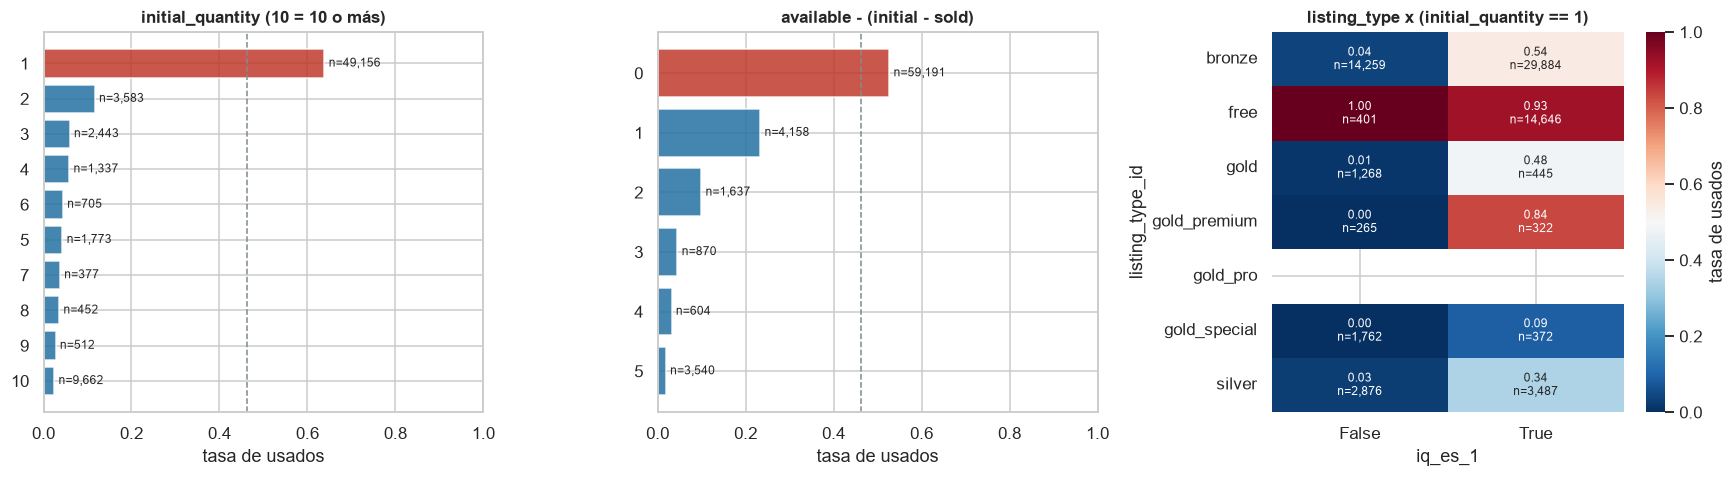



- Con `initial_quantity` = 1 la tasa de usados es 63.9%, con más de una unidad
  cae a 4.9%. Un usado es casi siempre una unidad única.
- **Relación oculta, stock repuesto**: en teoría `available = initial - sold`. En
  10,809 items `available` es mayor a lo esperado (el vendedor repuso stock) y en
  esos casos la tasa de usados es 11.6%. Es una huella de comercio.
- La interacción con `listing_type_id` es fuerte: un `bronze` con stock 1 es ~54%
  usado, pero con más stock baja a ~4%. Un `free` es usado casi siempre, incluso con
  varias unidades. Los árboles capturan este cruce solos.
- **Relación oculta, `gold_premium`**: sola parece neutra (~46% usados), pero
  esconde dos poblaciones opuestas. Con más de una unidad es 0% usado y con stock 1
  es ~84% usado (bienes caros de unidad única, como autos o inmuebles, publicados
  con la mejor exposición).
- Haber vendido algo también empuja a "nuevo":

|                |   mean |   size |
|:---------------|-------:|-------:|
| (False, False) |  0.06  |  13350 |
| (False, True)  |  0.03  |   7494 |
| (True, False)  |  0.677 |  44748 |
| (True, True)   |  0.246 |   4408 |


## 7. Precio



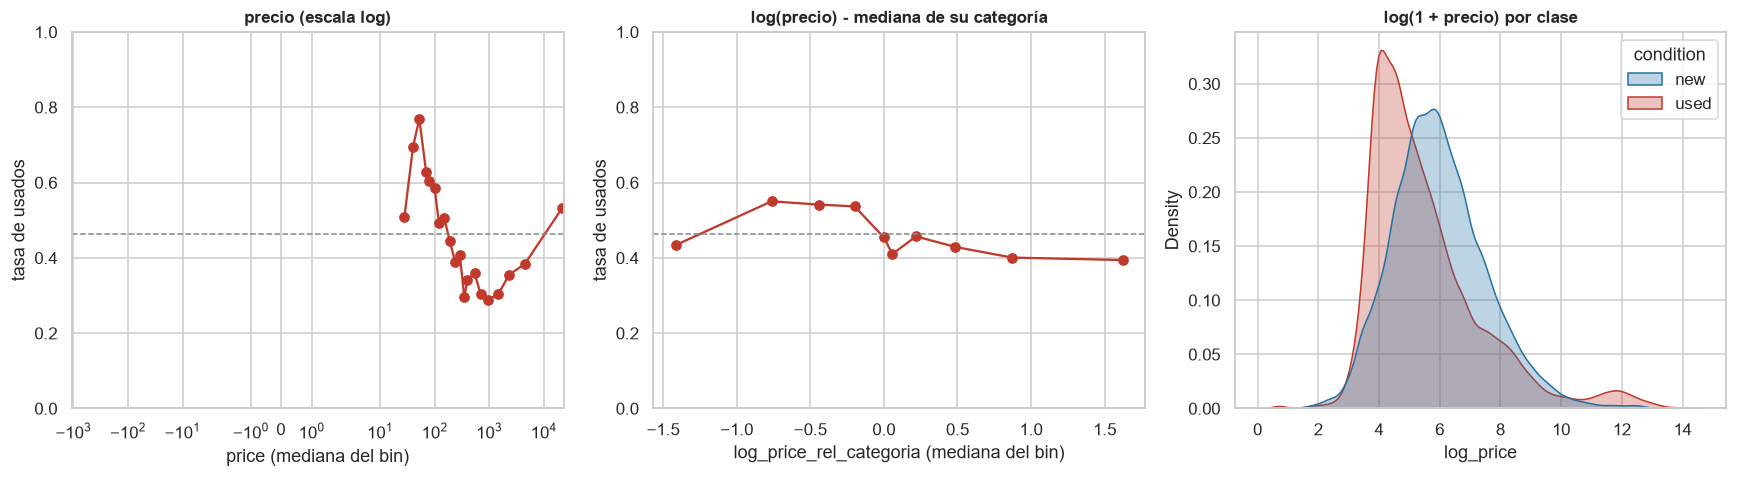



La relación precio y condición no es monótona: los usados se concentran en precios
bajos (libros, revistas, discos entre 35 y 100 pesos) y vuelven a subir en precios
muy altos (autos e inmuebles clasificados). El tramo medio es mayormente nuevo.


### Psicología de precios

|                     |     n |   usados_si_true |   usados_si_false |
|:--------------------|------:|-----------------:|------------------:|
| price_con_decimales |  9613 |            0.188 |             0.507 |
| price_termina_en_9  | 10134 |            0.233 |             0.502 |
| price_multiplo_100  | 15460 |            0.652 |             0.41  |

**Relación oculta**: el *formato* del precio delata al tipo de vendedor. Los
comercios usan precios con centavos o terminados en 9 (199.99, 349) y son
mayormente nuevos. Los particulares redondean a múltiplos de 100 y son mayormente
usados.


## 8. Variables temporales



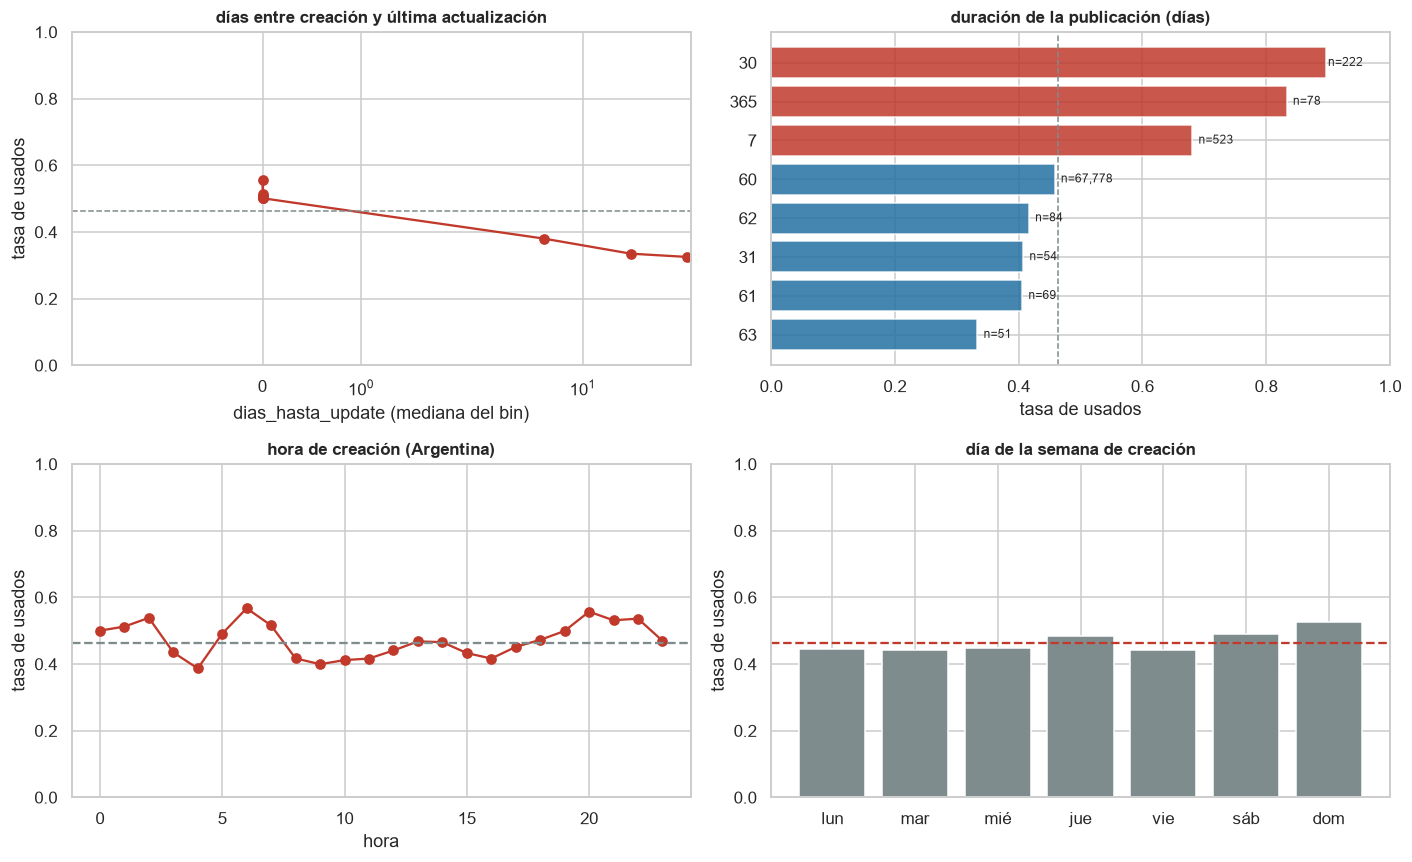



- Los items se crearon entre 2013-05-21 y 2015-10-15, casi
  todos entre agosto y octubre de 2015. La fecha en sí no tiene tendencia.
- Los items que se actualizaron días después de creados son más nuevos: el
  comerciante edita precio y stock, el particular publica y se olvida.
- La duración estándar es 60 días. Las de 30 días y 365 días son mayormente usados
  (formatos de clasificados y publicaciones gratuitas).
- Hay un patrón horario suave (hora argentina): de noche, entre las 19 y las 2, y
  los fines de semana publican más particulares (más usados); entre las 8 y las 18
  de lunes a viernes predominan los comercios.


In [3]:
variables.categoricas(ctx)
variables.stock(ctx)
variables.precio(ctx)
variables.temporal(ctx)
ctx.reporte.mostrar()


## 9. Texto: título y garantía



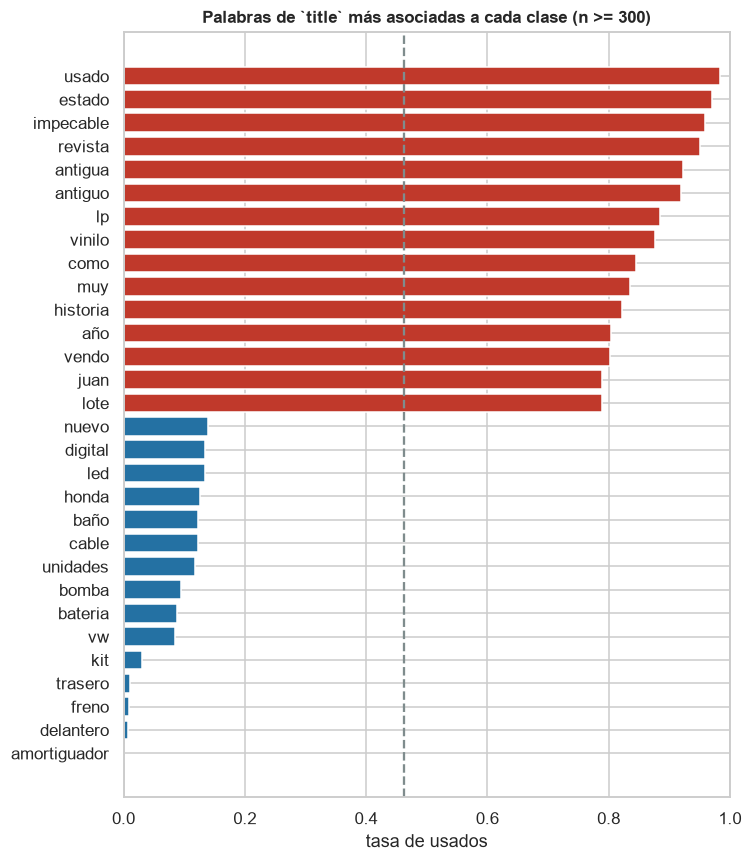

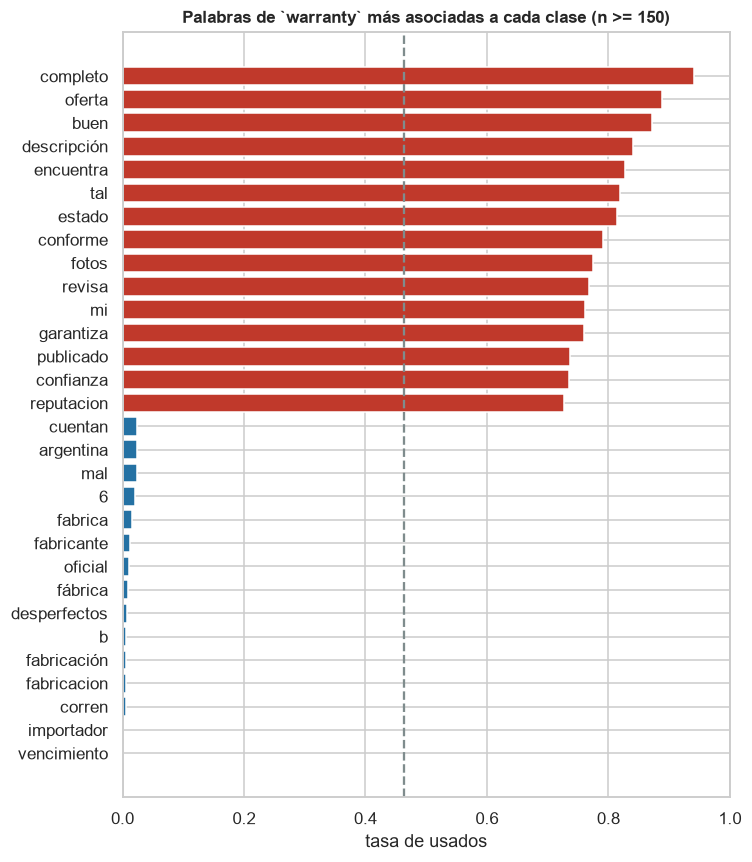

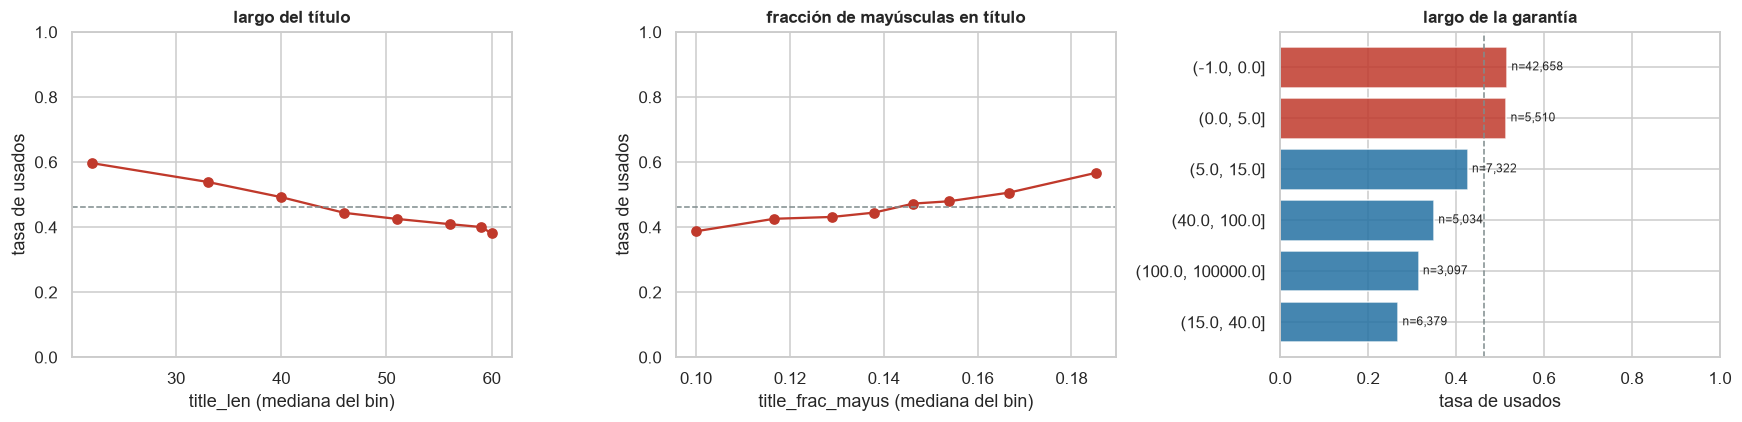



El texto es muy informativo y complementa a las variables estructuradas:

- **Título**: aparecen palabras explícitas ("usado", "impecable", "excelente estado")
  pero sobre todo el *tipo de producto*. Revistas, vinilos, LPs, libros y cosas
  "antiguas" son usados; repuestos de auto (amortiguador, freno, kit), electrónica
  (led, usb, cargador) y textiles son nuevos. Artículos como "el", "la", "los"
  aparecen como usados porque son típicos de títulos de libros y discos.
- **Garantía**: los nuevos hablan de "fabricación", "fábrica", "oficial",
  "importador", "meses". Los usados escriben frases sobre "estado", "fotos",
  "reputación", "conforme" (el vendedor responde por su palabra, no por un
  fabricante). Una garantía corta o vacía no discrimina; una de 15 a 40 caracteres
  ("6 meses de garantía") es fuertemente nueva.
- Títulos cortos y con muchas mayúsculas son más de particulares.

Esto sugiere sumar TF-IDF de título y garantía (o un modelo lineal sobre texto cuya
predicción out-of-fold entre como feature al modelo de árboles).


## 10. Señales semánticas: palabras clave y ficha técnica



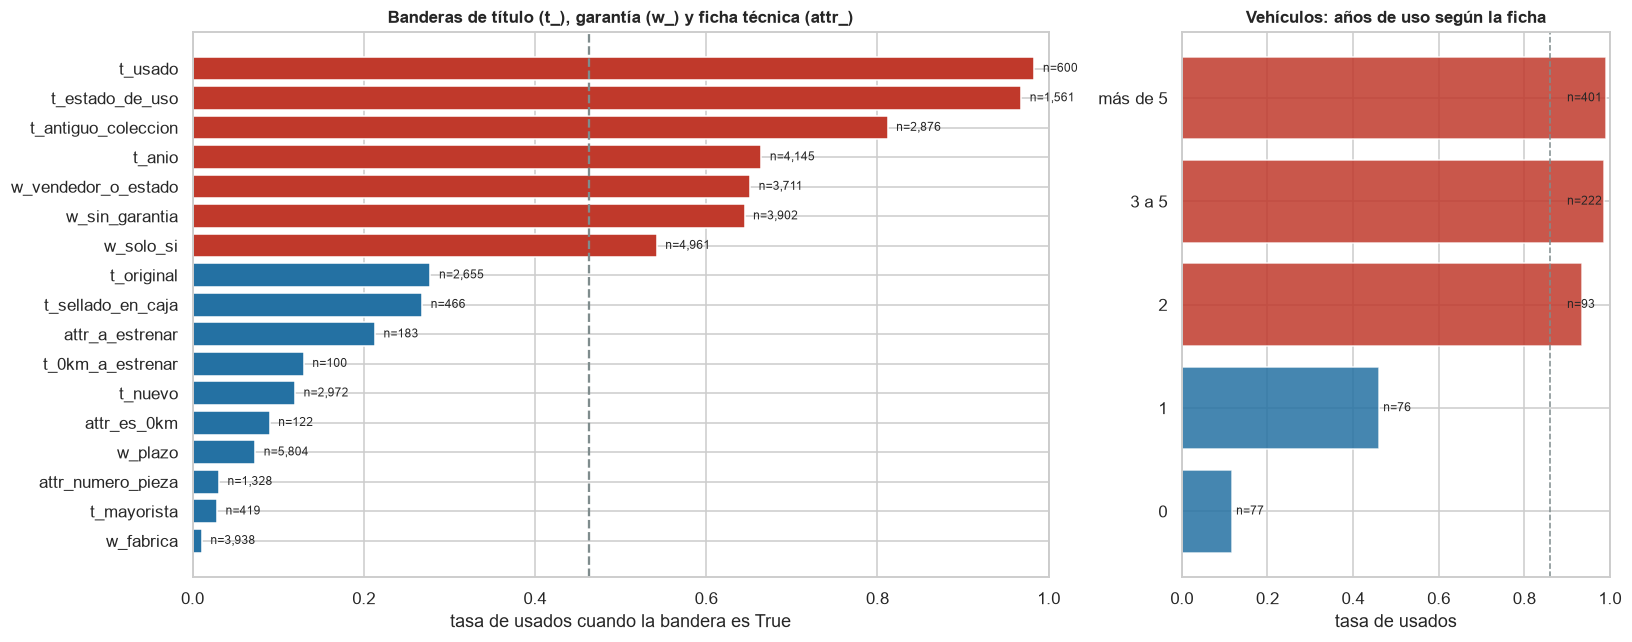



|                     |    n |   usados_si_true |   usados_si_false |
|:--------------------|-----:|-----------------:|------------------:|
| w_fabrica           | 3938 |            0.011 |             0.49  |
| t_mayorista         |  419 |            0.029 |             0.466 |
| attr_numero_pieza   | 1328 |            0.031 |             0.471 |
| w_plazo             | 5804 |            0.073 |             0.498 |
| attr_es_0km         |  122 |            0.09  |             0.464 |
| t_nuevo             | 2972 |            0.12  |             0.478 |
| t_0km_a_estrenar    |  100 |            0.13  |             0.464 |
| attr_a_estrenar     |  183 |            0.213 |             0.464 |
| t_sellado_en_caja   |  466 |            0.268 |             0.464 |
| t_original          | 2655 |            0.278 |             0.47  |
| w_solo_si           | 4961 |            0.542 |             0.457 |
| w_sin_garantia      | 3902 |            0.645 |             0.452 |
| w_vendedor_o_estado | 3711 |            0.651 |             0.452 |
| t_anio              | 4145 |            0.664 |             0.45  |
| t_antiguo_coleccion | 2876 |            0.812 |             0.448 |
| t_estado_de_uso     | 1561 |            0.968 |             0.452 |
| t_usado             |  600 |            0.983 |             0.459 |

Banderas simples sobre el texto y la ficha técnica capturan buena parte de lo que
"dice" la publicación. Algunas son casi deterministas aunque cubren pocos items:

- **Título**: "usado" y las descripciones de estado ("como nuevo", "impecable",
  "poco uso") son ~97% usados. Hay que separar "como nuevo" de "nuevo": el primero
  describe algo usado, el segundo baja la tasa a ~12%. La venta mayorista ("x 10
  unidades", "por mayor") es casi siempre de nuevos. "Antiguo", "colección" o un año
  en el título apuntan a objetos usados (discos, revistas, antigüedades).
- **Garantía**: lo que importa es *quién* garantiza. Si la garantía es de fábrica,
  oficial o del importador, el item es nuevo (~1% usados). Si tiene un plazo
  concreto, también (~7%). Si el vendedor habla de su reputación o de que el
  producto funciona, es usado (~65%). Un "Sí" a secas no informa nada.
- **Ficha técnica**: en vehículos, los del año son mayormente nuevos (~12% usados),
  con un año de uso quedan en la mitad y desde 2 años de uso son ~99% usados. En inmuebles, "A estrenar" baja la tasa al
  ~21%. El número de pieza identifica repuestos nuevos (~3%).

Como cada bandera cubre pocos items, el aporte al accuracy global va a ser menor que
el de las variables de stock o vendedor, pero resuelven casos donde esas variables
dudan (por ejemplo un particular que vende algo nuevo en caja).


## 11. Formato de las fotos



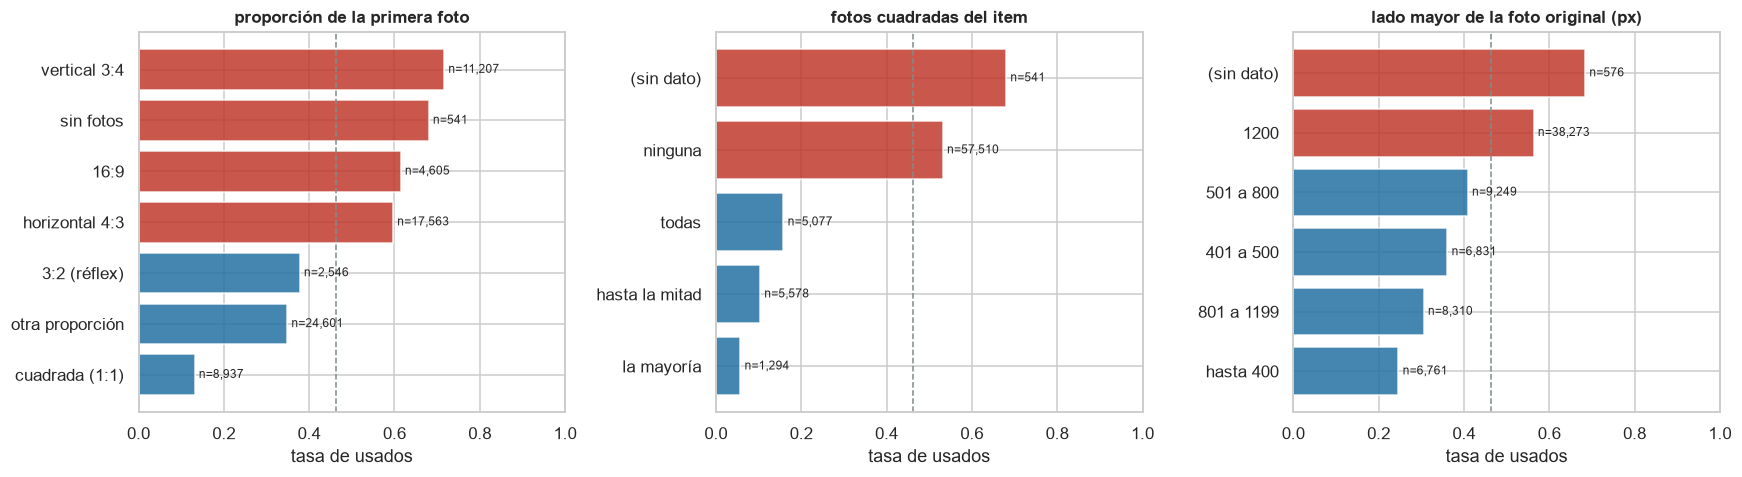



**Relación oculta**: la proporción de la foto delata cómo se sacó. Una foto cuadrada
es de catálogo o de estudio y solo el 13.1% de esos items es usado. Una foto
vertical 3:4 es de celular (71.6% usados) y una horizontal 4:3 es de cámara
compacta (59.7%). La proporción 3:2, propia de cámaras réflex, vuelve a ser
más de comercio (37.8%).

La resolución va en el mismo sentido: las fotos que llegan al tope de 1200 px son
fotos caseras subidas sin procesar, mientras que las de comercios suelen venir
recortadas y achicadas. Ninguna de estas variables mira el contenido de la imagen,
solo sus dimensiones.


In [4]:
variables.texto(ctx)
variables.senales_semanticas(ctx)
contexto.fotos(ctx)
ctx.reporte.mostrar()

## Por último, lo que dicen las otras publicaciones

La señal más fuerte no está en el item sino en quién lo publica y en qué categoría.


## 12. Vendedores: la relación oculta más fuerte



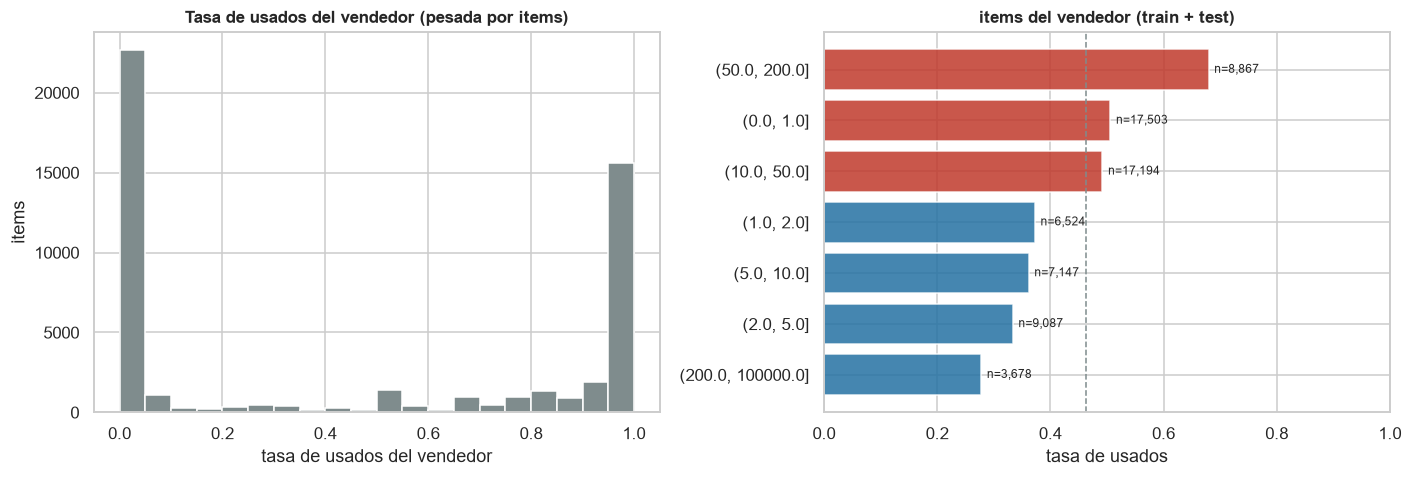



Hay 27,949 vendedores en train. Entre los items de vendedores
con más de un item, el 69.6% pertenece a vendedores **puros** (todo nuevo o
todo usado): la distribución es una U casi perfecta. Un vendedor es un comercio o un
particular, rara vez ambas cosas.

Si para cada item se predice la clase mayoritaria de los *otros* items del mismo
vendedor, el accuracy es **0.923** sobre el 71.5% de train que
tiene vendedor repetido. Y 71.6% de los
items de test tienen vendedor en train. Un target encoding out-of-fold por vendedor
va a ser probablemente la feature más importante.

El tamaño del vendedor no es monótono: los de 2 a 10 items son mayormente nuevos,
los de 50 a 200 vuelven a ser usados (revendedores de libros, discos, coleccionables)
y los más grandes son comercios.


### Perfil del vendedor (sin usar el target)



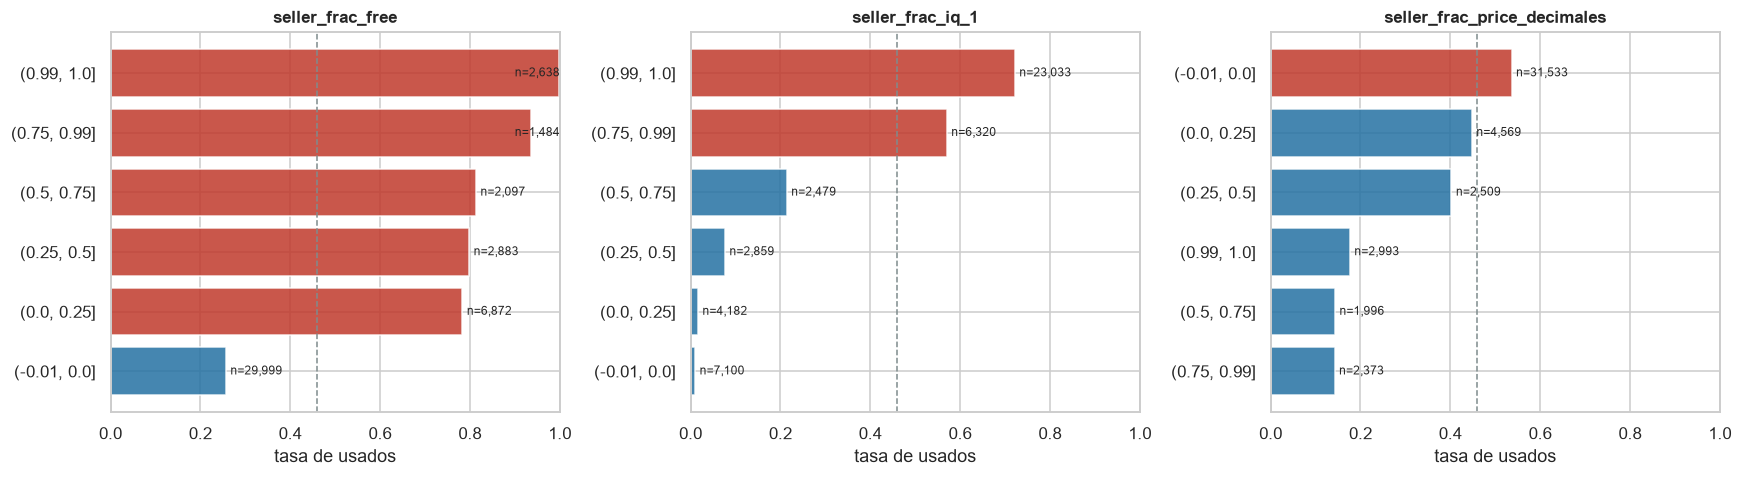



*Solo vendedores con 3 o más items (train + test)*

Agregando por vendedor las variables del item (sobre train + test, sin mirar el
target) se obtiene un perfil del vendedor que generaliza a vendedores no vistos.

**Relación oculta**: lo que hace un vendedor en *sus otras* publicaciones dice más
que el item mismo. Si se toman solo los items que **no** son `free`, los de
vendedores que alguna vez publicaron gratis son 70.1% usados, contra
26.3% de los vendedores que nunca lo hicieron. Lo mismo con la fracción
de items con stock 1 y la fracción de precios con centavos.


## 13. Comportamiento del vendedor en sus otras publicaciones



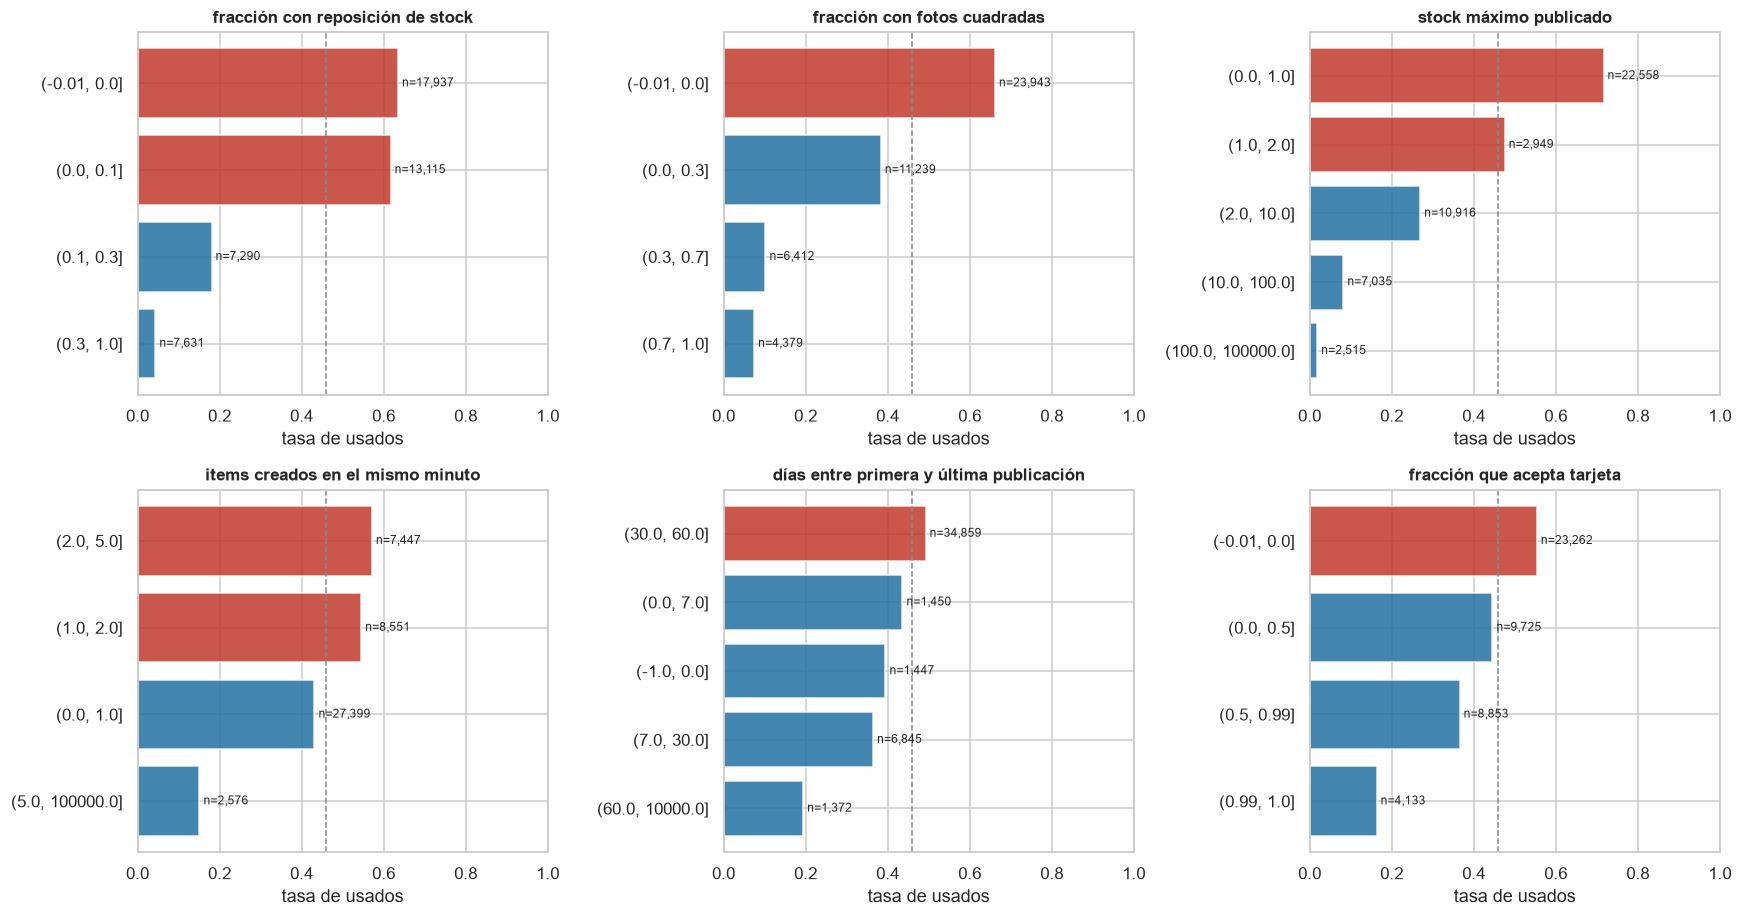



*Solo vendedores con 3 o más items (train + test)*

El perfil del vendedor se puede enriquecer mucho más allá de `free` y stock 1. Todo
se calcula sobre train + test juntos y sin el target, así que también existe para
los vendedores que solo aparecen en test.

- **Reposición de stock**: si el vendedor nunca repone, 63.5% de sus
  items son usados. Si repone en más del 30% de sus publicaciones, 4.4%.
- **Stock máximo**: un vendedor que nunca publicó más de 2 unidades de nada tiene
  65.3% de usados. Si alguna vez publicó más de 10, 6.3%.
- **Carga masiva**: más de 5 publicaciones creadas en el mismo minuto indican una
  herramienta de carga, propia de comercios (15.1% usados).
- **Fotos del vendedor**: quien usa fotos cuadradas en otras publicaciones es
  comercio aunque en este item no lo haga. Entre los items *sin* foto cuadrada, los
  de vendedores con más del 30% de publicaciones con fotos cuadradas son
  12.4% usados, contra 60.3% de los
  vendedores que nunca las usan.

Estas variables explican por qué un mismo item (stock 1, `bronze`, sin garantía)
puede ser nuevo o usado: depende de quién lo publica.


## 14. Categorías



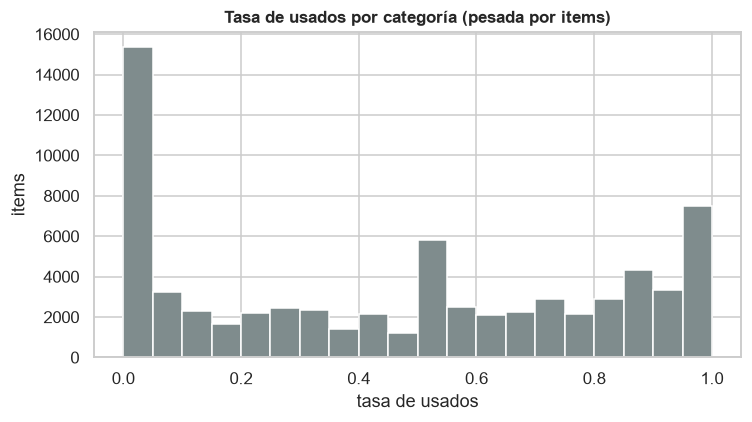



Hay 9,570 categorías (hojas del árbol de MercadoLibre, sin
nombre). Predecir la clase mayoritaria de los otros items de la misma categoría da
accuracy **0.780** sobre el 94.7% de train evaluable. Entre las
categorías con 20 o más items, el 9.4% de los items está en categorías
puras. 94.7% de los items de test
tienen categoría vista en train. Categorías más grandes:

| category_id   |   tasa_usados |    n |
|:--------------|--------------:|-----:|
| MLA1227       |         0.508 | 3180 |
| MLA2044       |         0.746 | 1359 |
| MLA41287      |         0.868 |  629 |
| MLA3530       |         0.402 |  542 |
| MLA2038       |         0.936 |  468 |
| MLA15171      |         0.624 |  410 |
| MLA15328      |         0.985 |  333 |
| MLA15204      |         0.47  |  319 |
| MLA1383       |         0.924 |  315 |
| MLA41269      |         0.914 |  303 |
| MLA2032       |         0.875 |  295 |
| MLA3361       |         0.363 |  284 |


## 15. Perfil por palabra del título



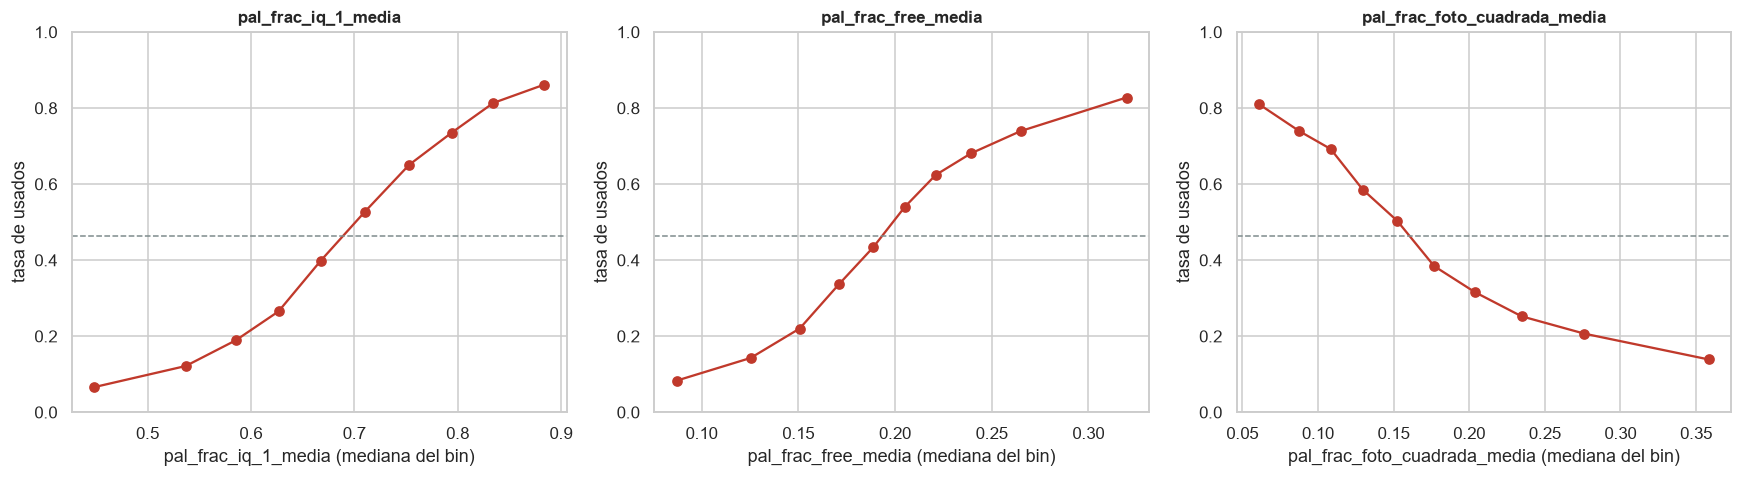



El título dice qué producto es, y hay productos que casi siempre son usados (un
vinilo, una revista) o nuevos (un repuesto, un cargador). Para capturarlo **sin
usar el target** se arma un perfil por palabra:

1. Para cada palabra se mira cómo se publican los *otros* items que la contienen:
   qué fracción es gratuita, de stock 1, con precio con centavos, con reposición de
   stock o con foto cuadrada. El propio item se excluye de ese cálculo.
2. Cada título se resume con el promedio y el máximo sobre sus palabras.

El resultado ordena muy bien los items: en el decil más bajo de
`pal_frac_iq_1_media` hay 6.6% de usados y en el más alto
86.2%. Solo se consideran palabras presentes en al menos
5 títulos.

Es la versión "legal" de un target encoding del título: usa como guía variables
que también existen en test (tipo de publicación, stock) en lugar de la condición.


In [5]:
relaciones.vendedores(ctx)
contexto.comportamiento_vendedor(ctx)
relaciones.categorias(ctx)
contexto.perfil_por_palabra(ctx)
ctx.reporte.mostrar()


## 16. Ranking de variables y correlaciones

Para cada variable, información mutua con el target y accuracy (CV de 3 folds) de un
árbol de profundidad 4 que solo ve esa variable:

|                             |   mutual_info |   acc_arbol_1_variable |
|:----------------------------|--------------:|-----------------------:|
| seller_frac_free            |         0.189 |                  0.774 |
| seller_frac_iq_1            |         0.24  |                  0.769 |
| cat_frac_iq_1               |         0.211 |                  0.759 |
| pal_frac_iq_1_media         |         0.183 |                  0.754 |
| seller_max_initial_quantity |         0.157 |                  0.74  |
| iq_es_1                     |         0.182 |                  0.732 |
| initial_quantity            |         0.179 |                  0.732 |
| available_quantity          |         0.171 |                  0.727 |
| cat_frac_free               |         0.192 |                  0.726 |
| pal_frac_free_media         |         0.138 |                  0.719 |
| seller_frac_vendio          |         0.206 |                  0.718 |
| cat_frac_vendio             |         0.163 |                  0.713 |
| seller_frac_repuso_stock    |         0.186 |                  0.707 |
| seller_frac_foto_cuadrada   |         0.156 |                  0.679 |
| pic0_aspecto                |         0.113 |                  0.671 |
| log_price                   |         0.148 |                  0.644 |
| pic_lado_max                |         0.06  |                  0.615 |
| seller_n_items              |         0.094 |                  0.61  |
| cat_n_items                 |         0.085 |                  0.608 |
| price_multiplo_100          |         0.025 |                  0.604 |



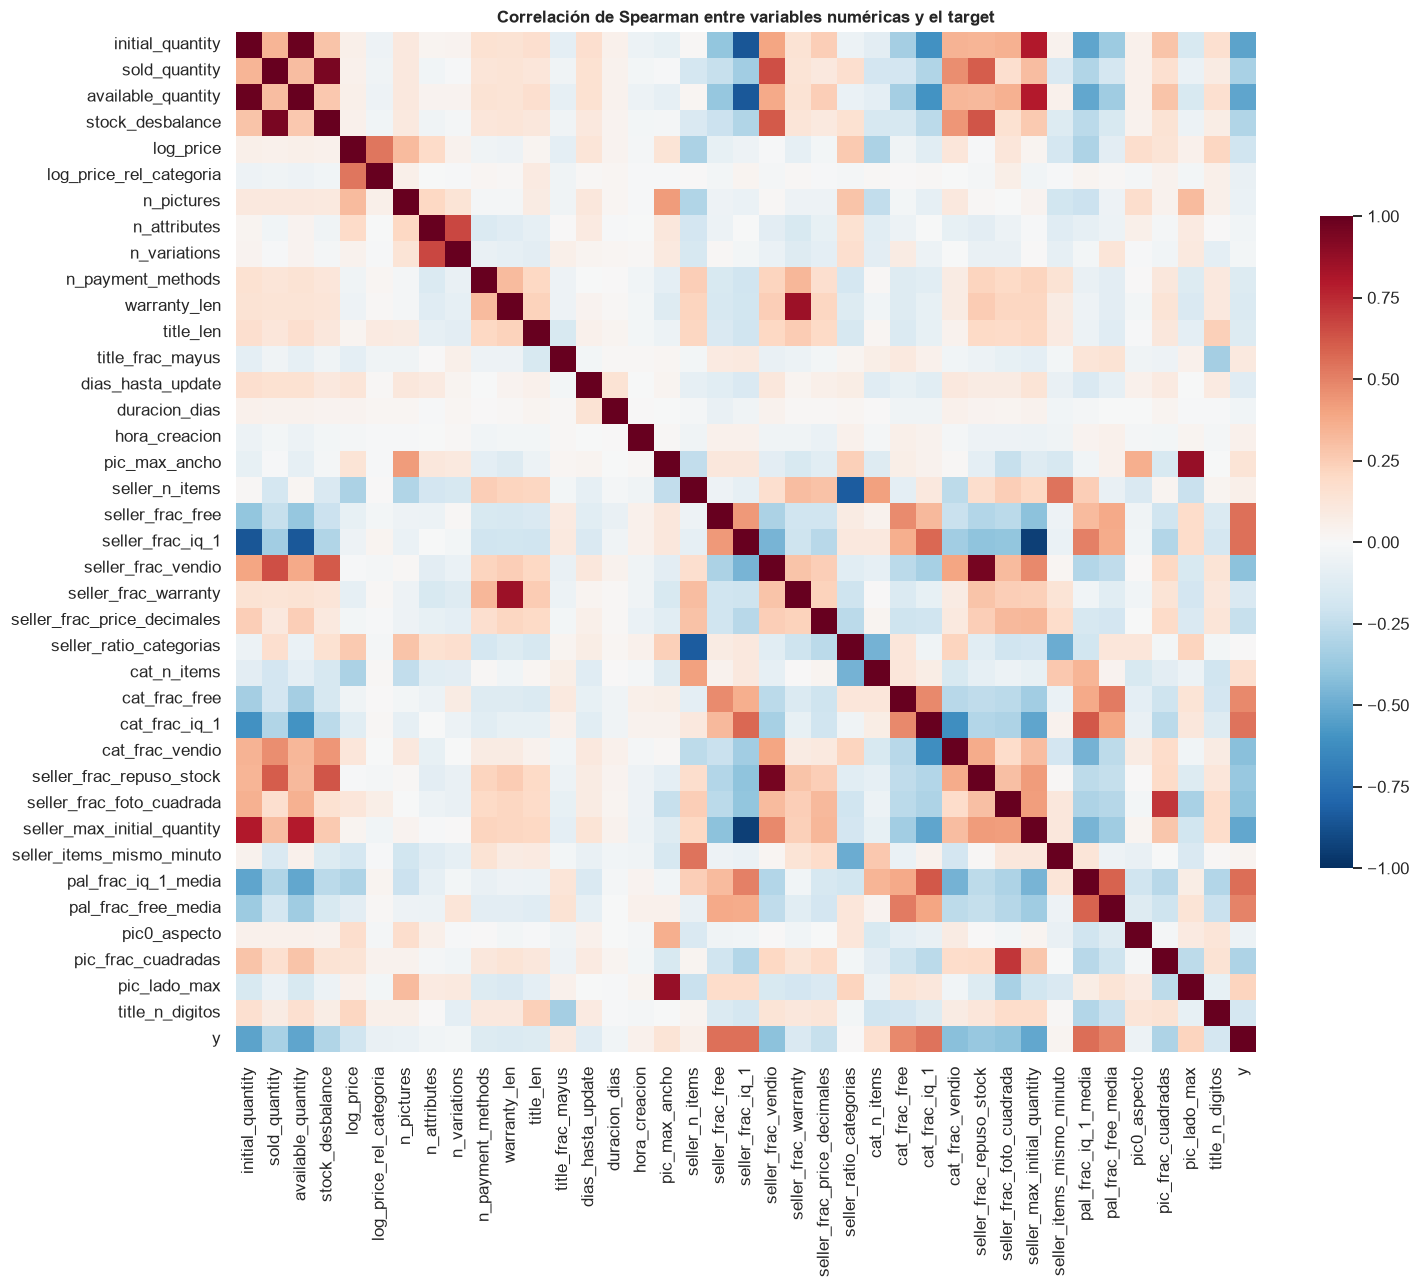



Las variables individuales más predictivas (`seller_frac_free` a la cabeza) son perfiles
agregados del vendedor y de la categoría, por encima de cualquier atributo del item.
Entre las del item lideran `initial_quantity`/`available_quantity` y luego el precio.

En la matriz de correlación:

- `initial_quantity` y `available_quantity` son casi la misma variable (0.99).
  `sold_quantity` va por otro lado (0.34).
- `seller_frac_iq_1` está muy correlacionada con `initial_quantity` (-0.86), pero
  solo moderadamente con `seller_frac_free` (0.43). Ambas tienen la misma
  correlación con el target (0.55), así que capturan facetas distintas del
  vendedor particular y conviene mantener las dos.
- Las variables de "profesionalismo" (`seller_frac_warranty`,
  `seller_frac_price_decimales`, `n_payment_methods`) apuntan en la misma dirección
  pero se correlacionan poco entre sí (0.17 a 0.33): son señales débiles e
  independientes que un modelo de árboles puede sumar.


## 17. Control de leakage

Todas las features se construyen cumpliendo estas reglas:

- Solo usan campos presentes en el test. `condition` se descarta antes de calcular
  cualquier agregado.
- Los agregados por vendedor, categoría o palabra se calculan sobre train + test
  juntos, así que significan lo mismo en ambos y existen para vendedores y
  categorías que solo aparecen en test.
- El perfil por palabra excluye al propio item (leave-one-out).

`run_verificar_leakage.py` lo comprueba de forma automática con tres controles:

| Control | Qué verifica |
|---|---|
| Invarianza al target | las features no cambian si se mezcla `condition` al azar ni si se elimina la columna |
| Mismas columnas | train y test tienen exactamente las mismas features |
| Disponibilidad en test | ninguna feature tiene más nulos en test que en train |

Para confirmar que el control sirve, se le inyectó una feature tramposa (la tasa de
usados por vendedor) y la detectó por los tres caminos.


### Features que sí usan el target

La tasa de usados por vendedor y por categoría y los vecinos por título son
muy informativos, pero usan `condition`. Viven aparte, en `target_encoding.py`, y
se calculan con folds anidados:

- Las filas a predecir (validación o test) se codifican con las etiquetas del
  entrenamiento. Sus propias etiquetas no intervienen.
- Las filas de entrenamiento se codifican por sub-folds: cada una recibe valores
  calculados con las etiquetas de los otros sub-folds.

No se usa leave-one-out porque ahí el valor de cada fila depende, al revés, de su
propia etiqueta, y un modelo de árboles puede deducirla. El verificador suma dos
controles para esta parte:

| Control | Qué verifica | Qué error atrapa |
|---|---|---|
| Sin etiqueta propia | al invertir las etiquetas de un sub-fold, sus features no cambian | codificar el entrenamiento con sus propias etiquetas, o con leave-one-out |
| Target mezclado | con etiquetas al azar, el accuracy de validación cae al de la clase mayoritaria | calcular el encoding con todas las etiquetas antes de separar la validación |

Los dos controles se probaron contra implementaciones tramposas. Con el encoding
calculado de forma global, el modelo "acierta" 79% con etiquetas al azar (lo
esperable es 53%). Con la implementación real da 51%.


In [6]:
relaciones.ranking_global(ctx)
contexto.control_de_leakage(ctx)
ctx.reporte.mostrar()